# Expensive coffee, richer farmers?
*Assignment 3 - Economics*

## Q1: Understand and explore the market

**Data:** `coffee_market.csv` — 300 independent selling periods in a stylised wholesale market for one grade of green coffee (synthetic teaching data).

> Assumptions given in the brief: price-taking buyers and sellers, market clearing, fixed quality, no inventory carry-over. `growing_conditions` is independent of buyers' preferences, incomes and unobserved demand disturbances; `buyer_activity` does not directly change producers' costs.

### Q1.1 First approach to data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide pandas 3.0 notices

coff_mark = pd.read_csv('data/coffee_market.csv')

# Colours (blue / orange / aqua) + different marker shapes, so groups never rely on colour alone
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
coff_mark.head()

,period_id,period_index,price_usd_kg,quantity_kt,growing_conditions,buyer_activity
0,M001,1,10.837531,133.302350,1.5,2.391855
1,M002,2,8.915661,67.150820,-1.5,-2.516137
2,M003,3,11.694981,88.019068,-1.5,-0.195789
3,M004,4,10.394216,101.971595,0.0,0.117742
4,M005,5,7.323098,95.714836,1.5,-1.148320


In [2]:
audit = pd.Series({
    "rows": len(coff_mark),
    "columns": coff_mark.shape[1],
    "missing cells": int(coff_mark.isna().sum().sum()),
    "duplicated rows": int(coff_mark.duplicated().sum()),
    "unique period_id": coff_mark["period_id"].nunique(),
    "period_id matches period_index": bool((coff_mark["period_id"].str[1:].astype(int) == coff_mark["period_index"]).all()),
    "non-positive prices": int((coff_mark["price_usd_kg"] <= 0).sum()),
    "non-positive quantities": int((coff_mark["quantity_kt"] <= 0).sum()),
    "distinct growing_conditions values": sorted(coff_mark["growing_conditions"].unique().tolist()),
    "distinct buyer_activity values": coff_mark["buyer_activity"].nunique(),
}, name="value")
display(audit.to_frame())
display(coff_mark.dtypes.to_frame("dtype"))
coff_mark["growing_conditions"].value_counts().sort_index().rename("periods").to_frame()

,value
rows,300
columns,6
missing cells,0
duplicated rows,0
unique period_id,300
period_id matches period_index,True
non-positive prices,0
non-positive quantities,0
distinct growing_conditions values,"[-1.5, 0.0, 1.5]"
distinct buyer_activity values,300


,dtype
period_id,object
period_index,int64
price_usd_kg,float64
quantity_kt,float64
growing_conditions,float64
buyer_activity,float64


,periods
growing_conditions,
-1.5,100
0.0,100
1.5,100


> The data is healthy and the description matches the content. No missing values or duplicated rows. In general the data is coherent as all prices and quantities are positive. This first step is fundamental so we can conclude all the analysis that's about to come represents behaviours and not data mistakes. 

**Important note**: Period id will not be analyzed as time because the description of the variable says "The index is not a historical trend". So time series are not part of this analysis.

### Q1.2 Sales revenue and descriptives

Revenue = price × quantity. Units: (US\$ per kg) × (thousand tonnes) = (US\$/kg) × (10⁶ kg) = **million US\$** per selling period.

In [3]:
coff_mark["revenue_musd"] = coff_mark["price_usd_kg"] * coff_mark["quantity_kt"]

vars_ = {"price_usd_kg": "Price (US$/kg)",
         "quantity_kt": "Quantity (thousand t)",
         "revenue_musd": "Revenue (million US$)"}
desc = (coff_mark[list(vars_)].describe(percentiles=[.25, .5, .75]).T
          .rename(index=vars_)
          [["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])
desc["CV (std/mean)"] = desc["std"] / desc["mean"]
desc.round(2)

/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_15025/1527124571.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  coff_mark["revenue_musd"] = coff_mark["price_usd_kg"] * coff_mark["quantity_kt"]
/var/folders/t9/0f6k77l54153159x

,count,mean,std,min,25%,50%,75%,max,CV (std/mean)
Price (US$/kg),300.0,10.01,2.22,5.17,8.50,10.03,11.47,14.99,0.22
Quantity (thousand t),300.0,100.01,18.46,64.15,85.27,100.40,115.42,138.60,0.18
Revenue (million US$),300.0,1022.83,357.98,382.92,718.70,969.61,1300.92,1858.19,0.35


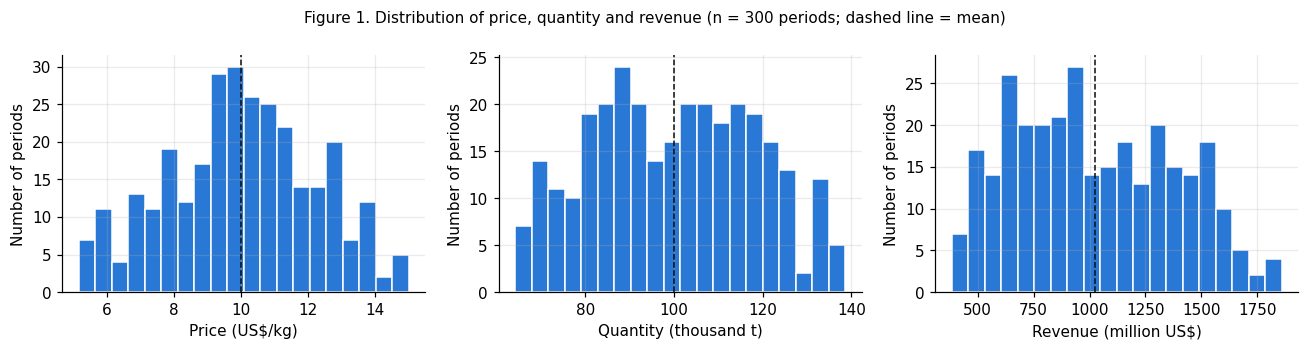

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (col, label) in zip(axes, vars_.items()):
    ax.hist(coff_mark[col], bins=20, color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(coff_mark[col].mean(), color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel(label); ax.set_ylabel("Number of periods")
fig.suptitle("Figure 1. Distribution of price, quantity and revenue (n = 300 periods; dashed line = mean)", fontsize=10)
fig.tight_layout(); plt.show()

Here we check for distribution (skew), outliers and variable fluctuation:
* The spread of the revenue is much bigger than that of price and quantity: 35% vs 22% and 18% 
    * Typical price: 10 USD per kg
    * Typical quantity: 100 thousand tonnes
    * Typical revenue: 1,022 million USD
* We don't observe any extreme periods so far

### Q1.3 Price-quantity relationship

We also fit the simplest linear relationship, $Q = a + b\,P$, treating all 300 points alike. This is the "naive" answer to *how does quantity move with price?*

Pooled fit: Q = 55.1 + 4.49·P   (kt per US$/kg)
Correlation(P, Q) = 0.54
'Elasticity' implied at the means (P̄=10.01, Q̄=100.0): 0.45


,n,P_mean,Q_mean
growing_conditions,,,
-1.5,100,11.57,91.69
0.0,100,10.20,102.04
1.5,100,8.25,106.31


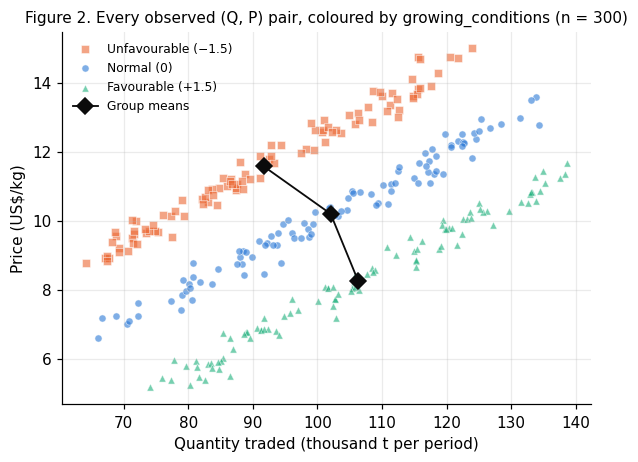

In [5]:
P, Q = coff_mark["price_usd_kg"], coff_mark["quantity_kt"]
b, a = np.polyfit(P, Q, 1)                       # Q = a + b*P
r = P.corr(Q)
naive_elast = b * P.mean() / Q.mean()            # slope × (P̄ / Q̄)

print(f"Pooled fit: Q = {a:.1f} + {b:.2f}·P   (kt per US$/kg)")
print(f"Correlation(P, Q) = {r:.2f}")
print(f"'Elasticity' implied at the means (P̄={P.mean():.2f}, Q̄={Q.mean():.1f}): {naive_elast:.2f}")

# Same points, coloured by growing_conditions (supply shifter), plus each group's mean
groups = {-1.5: ("Unfavourable (−1.5)", ORANGE, "s"), 0.0: ("Normal (0)", BLUE, "o"), 1.5: ("Favourable (+1.5)", AQUA, "^")}
means = (coff_mark.groupby("growing_conditions")
           .agg(n=("price_usd_kg", "size"), P_mean=("price_usd_kg", "mean"), Q_mean=("quantity_kt", "mean")))
display(means.round(2))

fig, ax = plt.subplots(figsize=(6.2, 4.4))
for g, (label, col, mk) in groups.items():
    sub = coff_mark[coff_mark["growing_conditions"] == g]
    ax.scatter(sub["quantity_kt"], sub["price_usd_kg"], s=22, color=col, marker=mk,
               alpha=0.6, edgecolor="white", linewidth=0.5, label=label)
ax.plot(means["Q_mean"], means["P_mean"], color=INK, marker="D", markersize=7, linewidth=1.2, label="Group means")
ax.set_xlabel("Quantity traded (thousand t per period)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 2. Every observed (Q, P) pair, coloured by growing_conditions (n = 300)", fontsize=10)
ax.legend(frameon=False, loc="upper left", fontsize=8); plt.show()

**What do we see when we colour the dots by `growing_conditions` (Figure 2)?**

> **First conclusion:** As the price increases, the quantity traded also increases (correlation 0.54). But it's not an isolated effect

* The graph was initially analyzed with an overall mean, but it does not make that much sense after plotting: The three groups of `growing_conditions` have clearly different behaviours

- **The cloud is really three bands.** Each harvest level forms its own narrow, upward-sloping band, and the bands are stacked side by side. What looks like a noisy pooled relationship (correlation 0.54) is mostly the mix of three different harvest situations.

- **Better harvests sit lower and further right.** The same price comes with more coffee traded when growing conditions are good. This is what we would expect if good weather shifts supply outward.

- **Within each band, price and quantity rise together.** Growing conditions are fixed inside a band, so this co-movement must come from the other driver, `buyer_activity` (demand shifting along a given supply).

- **The group means move the opposite way.** Going from poor to good harvests, the average price falls (11.57 → 10.20 → 8.25 US\$/kg) while the average quantity rises (91.7 → 102.0 → 106.3 kt). Since `growing_conditions` is independent of buyers, average demand is the same in all three groups. The diamonds therefore show how buyers react when only supply changes: cheaper coffee, more bought.

In [6]:
cols = ["price_usd_kg", "quantity_kt", "revenue_musd", "growing_conditions", "buyer_activity"]
coff_mark[cols].corr().round(2)

,price_usd_kg,quantity_kt,revenue_musd,growing_conditions,buyer_activity
price_usd_kg,1.00,0.54,0.89,-0.61,0.79
quantity_kt,0.54,1.00,0.85,0.32,0.93
revenue_musd,0.89,0.85,1.00,-0.21,0.97
growing_conditions,-0.61,0.32,-0.21,1.00,-0.02
buyer_activity,0.79,0.93,0.97,-0.02,1.00


> Price and quantity are both strongly correlated with `buyer_activity`
>
> `growing_conditions` correlates *negatively* with price but *positively* with quantity. In simpler words: favourable growing conditions create a scenario for cheaper and more abundant coffee.

In [7]:
print("Table 1: Averages by growing conditions (n = 100 per group)")
by_gc = (coff_mark.groupby("growing_conditions")
           .agg(periods=("price_usd_kg", "size"),
                mean_price=("price_usd_kg", "mean"),
                mean_quantity=("quantity_kt", "mean"),
                mean_revenue=("revenue_musd", "mean"),
                mean_buyer_activity=("buyer_activity", "mean"))
           .rename(index={-1.5: "Unfavourable (−1.5)", 0.0: "Normal (0)", 1.5: "Favourable (+1.5)"}))
by_gc.round(2)

Table 1: Averages by growing conditions (n = 100 per group)


,periods,mean_price,mean_quantity,mean_revenue,mean_buyer_activity
growing_conditions,,,,,
Unfavourable (−1.5),100,11.57,91.69,1088.90,-0.07
Normal (0),100,10.20,102.04,1070.36,0.20
Favourable (+1.5),100,8.25,106.31,909.22,-0.15


> Revenue is higher when the growing conditions are worse: High price, low quantity

**Finding (Q1)**

- Overall, P and Q go up together (correlation 0.54).
- By weather (Table 1):
  - Bad harvest: P 11.6 USD/kg, Q 91.7 kt, revenue 1,089 million USD.
  - Good harvest: P 8.2 USD/kg, Q 106.3 kt, revenue 909 million USD.
- Inside each colour the points still slope up.
- Each point is an equilibrium, where S meets D. Both curves move.
- So the upward slope is **not** demand, and it can't tell us how buyers react to a price rise.
- Why each output:
  - The audit shows the data are clean.
  - Figure 1 shows levels and spread.
  - Figure 2 (colours) shows the hidden pattern.
  - Table 1 gives the group numbers.
- Questions raised:
  - What shifts S and what shifts D?
  - Can weather help us find demand?
  - Why do bad harvests earn more?

---
## Q2: Develop an equilibrium explanation

### Q2.1 What an observed (Q, P) pair represents

In each selling period there is a demand curve $D(p; \text{buyer activity}, u_t)$ and a supply curve $S(p; \text{growing conditions}, v_t)$, where $u_t$ and $v_t$ are disturbances we **do not observe**. With price-taking and market clearing, the recorded pair $(Q_t, P_t)$ solves

$$D(P_t;\ \text{buyer activity}_t,\ u_t) \;=\; S(P_t;\ \text{growing conditions}_t,\ v_t) \;=\; Q_t .$$

So each row is the **intersection** of two curves. It is not a point that buyers picked on their own, and it is not one that sellers picked on their own.

**Movement along a curve and shift of a curve**
- *Movement along* a curve: the price changes while everything else in that curve's equation stays fixed (same buyer activity and same $u_t$ for demand). That is the thing we want to measure: "if the price rose, how much less would buyers purchase?"
- *Shift* of a curve: one of the conditions behind it changes (buyer activity, growing conditions, or an unobserved disturbance), so the whole curve moves. At **every** price, the quantity is different.

### Q2.2 Two alternative explanations for a higher coffee price

| | **Explanation A: stronger demand** | **Explanation B: weaker supply (bad harvest)** |
|---|---|---|
| What changes | `buyer_activity` ↑: foreign buyers want more at every price | `growing_conditions` ↓: less coffee is worth harvesting at every price |
| Curve that shifts | Demand shifts **right** | Supply shifts **left** |
| Movement along | the **unchanged supply** curve | the **unchanged demand** curve |
| Price | ↑ | ↑ |
| Quantity | **↑** | **↓** |
| Seller revenue | ↑ (P and Q both rise) | ambiguous: depends on how strongly buyers react to price |

**Key:** the price rises in both cases, so the price alone cannot tell the two explanations apart. The direction of the **quantity** change can.

> The diagrams below use *illustrative* linear curves in coffee-like units. They are not estimates

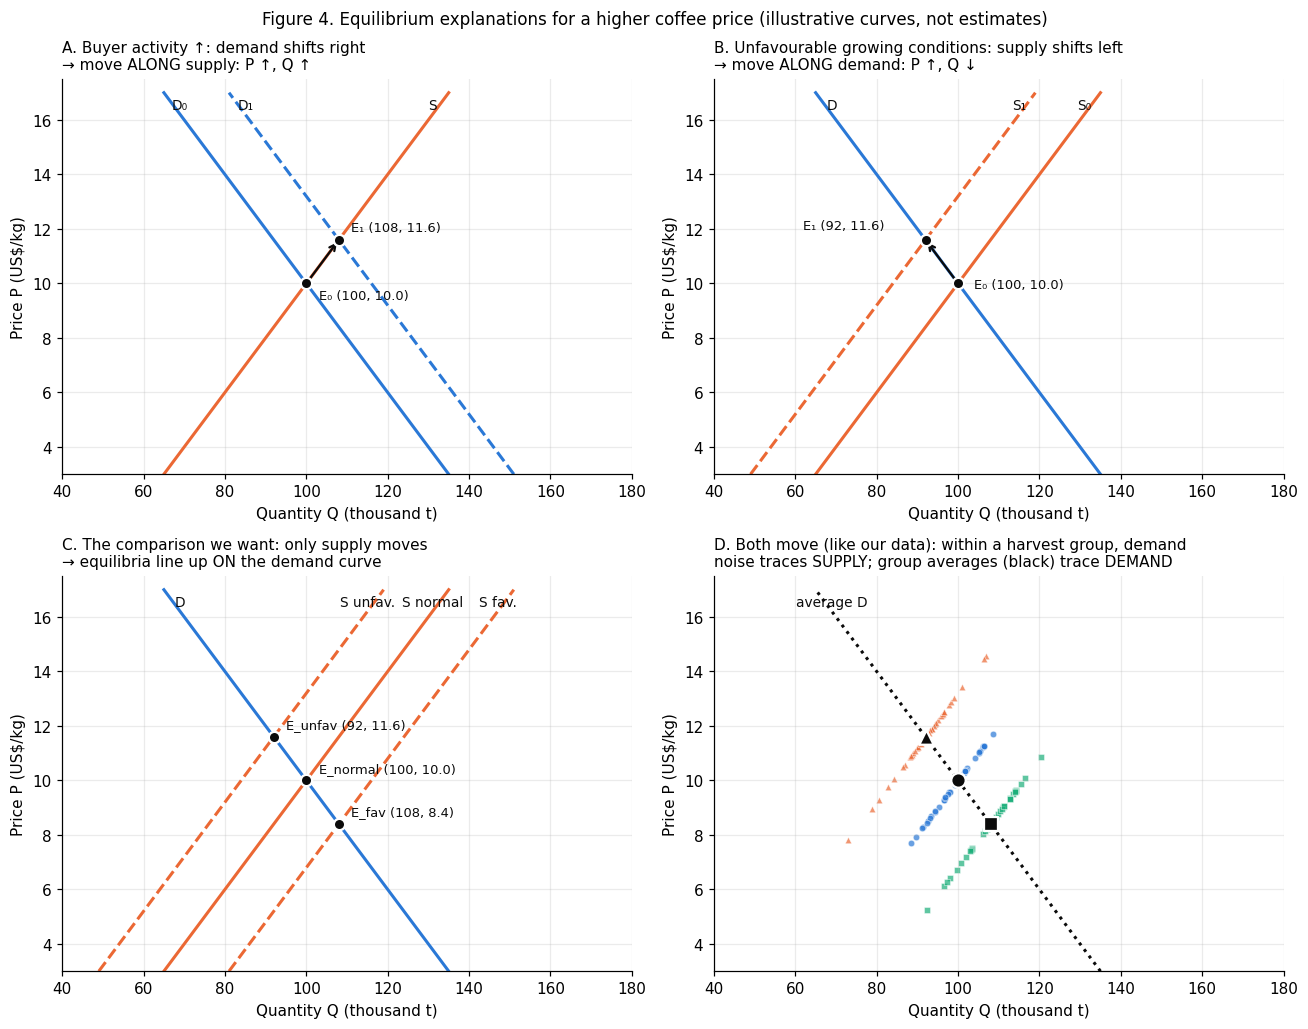

In [8]:
def demand(P, shift=0):  return 150 + shift - 5 * P     # illustrative only
def supply(P, shift=0):  return 50 + shift + 5 * P      # illustrative only
def eq(dS=0, dD=0):      # solve 150+dD-5P = 50+dS+5P
    P = (100 + dD - dS) / 10
    return demand(P, dD), P

Pg = np.linspace(3, 17, 100)
def curve(ax, f, shift, color, label, ls="-"):
    ax.plot(f(Pg, shift), Pg, color=color, lw=2, ls=ls)
    q = f(16.2, shift); ax.text(q, 16.4, label, color=INK, fontsize=9, ha="center")
def point(ax, Q, P, name, dx=3, dy=-0.6):
    ax.scatter([Q], [P], s=55, color=INK, zorder=5, edgecolor="white", linewidth=1.5)
    ax.text(Q + dx, P + dy, f"{name} ({Q:.0f}, {P:.1f})", fontsize=8.5, color=INK)
def frame(ax, title):
    ax.set_xlim(40, 180); ax.set_ylim(3, 17.5)
    ax.set_xlabel("Quantity Q (thousand t)"); ax.set_ylabel("Price P (US$/kg)")
    ax.set_title(title, fontsize=10, loc="left")

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))

# A: demand shift
ax = axes[0, 0]
curve(ax, supply, 0, ORANGE, "S")
curve(ax, demand, 0, BLUE, "D₀"); curve(ax, demand, 16, BLUE, "D₁", ls="--")
Q0, P0 = eq(); Q1, P1 = eq(dD=16)
point(ax, Q0, P0, "E₀"); point(ax, Q1, P1, "E₁", dy=0.3)
ax.annotate("", xy=(Q1, P1), xytext=(Q0, P0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
frame(ax, "A. Buyer activity ↑: demand shifts right\n→ move ALONG supply: P ↑, Q ↑")

# B: supply shift
ax = axes[0, 1]
curve(ax, demand, 0, BLUE, "D")
curve(ax, supply, 0, ORANGE, "S₀"); curve(ax, supply, -16, ORANGE, "S₁", ls="--")
Q1, P1 = eq(dS=-16)
point(ax, Q0, P0, "E₀", dx=4, dy=-0.2); point(ax, Q1, P1, "E₁", dx=-30, dy=0.4)
ax.annotate("", xy=(Q1, P1), xytext=(Q0, P0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
frame(ax, "B. Unfavourable growing conditions: supply shifts left\n→ move ALONG demand: P ↑, Q ↓")

# C: supply shifts only, demand fixed -> equilibria trace demand
ax = axes[1, 0]
curve(ax, demand, 0, BLUE, "D")
for s, lab in [(-16, "S unfav."), (0, "S normal"), (16, "S fav.")]:
    curve(ax, supply, s, ORANGE, lab, ls="-" if s == 0 else "--")
pts = [eq(dS=s) for s in (-16, 0, 16)]
for (q, p), lab in zip(pts, ["E_unfav", "E_normal", "E_fav"]):
    point(ax, q, p, lab, dx=3, dy=0.3)
frame(ax, "C. The comparison we want: only supply moves\n→ equilibria line up ON the demand curve")

# D: both shift -> each supply curve traced by demand noise
ax = axes[1, 1]
rng = np.random.default_rng(1)
for s, colr, mk in [(-16, ORANGE, "^"), (0, BLUE, "o"), (16, AQUA, "s")]:
    dshift = rng.normal(0, 14, 40)
    qs, ps = zip(*[eq(dS=s, dD=d) for d in dshift])
    ax.scatter(qs, ps, s=18, color=colr, marker=mk, alpha=0.7, edgecolor="white", linewidth=0.4)
    q, p = eq(dS=s); ax.scatter([q], [p], s=90, color=INK, marker=mk, zorder=5, edgecolor="white", linewidth=1.5)
curve(ax, demand, 0, INK, "average D", ls=":")
frame(ax, "D. Both move (like our data): within a harvest group, demand\nnoise traces SUPPLY; group averages (black) trace DEMAND")

fig.suptitle("Figure 3. Equilibrium explanations for a higher coffee price (illustrative curves, not estimates)", fontsize=11)
fig.tight_layout(); plt.show()

### Q2.3 The proposed comparison

Compare market outcomes **across growing-conditions groups** (unfavourable −1.5, normal 0, favourable +1.5), using each group's **average** price and quantity. The change in average quantity divided by the change in average price, between harvest groups, measures how buyers respond to price: a movement along demand.

**It is informative** because growing conditions shift **supply only**. Comparing harvest groups therefore moves the market *along* the demand curve, exactly as in panel C.

| | |
|---|---|
| **What changes across the groups** | Growing conditions → the supply curve → equilibrium price (and, through it, quantity). |
| **What must remain comparable** | Everything behind demand: buyer activity, buyers' incomes and preferences, outside options, and the *unobserved* demand disturbances $u_t$. Also the product (fixed quality) and the market (same buyers and sellers). |
| **Assumptions that justify it** | (1) **Relevance**: growing conditions really shift supply, so prices differ across groups. (2) **Exclusion**: growing conditions affect buyers only through the price; they do not enter the demand curve. (3) **Independence**: growing conditions are unrelated to buyer activity and to unobserved demand shocks.  (4) A **stable demand curve**, approximately linear over the observed range. |

### Q2.4 What if demand also moves for reasons we do not observe?

Demand disturbances $u_t$ do not ruin the comparison, as long as they are **unrelated to growing conditions**:
- In any single period, demand noise moves the point off the "average" demand curve, so one period on its own tells us little.
- But weather does not "know" what buyers are doing. Each harvest group is therefore a mix of good, normal and bad demand periods, **in the same proportions** on average. Averaging within each group cancels the demand noise (black markers in panel D), and the remaining difference between group averages is caused by supply.

**When it would fail:**
- If growing conditions were correlated with demand. For example, a weather event that also hits buyers' economies, or buyers who stockpile when they hear about a bad harvest.
- If groups were too small for the averaging to work. Here we have 100 periods per group.
- If supply shifted for other reasons that happen to coincide with demand shocks.

In [9]:
print("Table 2: Buyer activity by growing conditions")
print(coff_mark.groupby("growing_conditions")["buyer_activity"].agg(["mean", "std", "count"]).round(2))

Table 2: Buyer activity by growing conditions
                    mean   std  count
growing_conditions                   
-1.5               -0.07  1.69    100
 0.0                0.20  1.67    100
 1.5               -0.15  1.76    100


**Balance check (Table 2)**
- Buyer activity means: −0.07, 0.20, −0.15, with a spread of about 1.7.
- Similar across groups, so demand is comparable.

**Unobserved shocks**
- Fine if they're unrelated to weather: they average out, adding noise but no bias.
- 100 periods per group keeps the noise small.
- It would break if weather affected buyers.
- This can't be checked, only assumed.

---
## Q3: Measure the demand response

### Q3.1 The idea

Weather moves the market **along** the demand curve (Q2, panel C). So:

$$\text{demand slope} \;=\; \frac{\Delta\ \text{average quantity across harvest groups}}{\Delta\ \text{average price across harvest groups}} \quad [\text{kt per US\$/kg}]$$

We implement this in two versions:
1. **Simple comparison:** raw group means, unfavourable versus favourable harvest. No modelling at all.
2. **Adjusted comparison:** the same ratio after removing the part of each group's P and Q explained by the *observed* demand shifter `buyer_activity`. Buyer activity is independent of the weather, so this does not change *what* we measure. It removes noise and the small chance imbalances between groups.

In [10]:
gm = coff_mark.groupby("growing_conditions")[["price_usd_kg", "quantity_kt", "buyer_activity"]].mean()
dQ = gm.loc[-1.5, "quantity_kt"] - gm.loc[1.5, "quantity_kt"]
dP = gm.loc[-1.5, "price_usd_kg"] - gm.loc[1.5, "price_usd_kg"]
slope_simple = dQ / dP
print("Unfavourable vs favourable harvest (raw group means):")
print(f"  ΔQ = {dQ:.2f} kt,  ΔP = {dP:.2f} US$/kg  →  slope = {slope_simple:.2f} kt per US$/kg")

Unfavourable vs favourable harvest (raw group means):
  ΔQ = -14.63 kt,  ΔP = 3.32 US$/kg  →  slope = -4.40 kt per US$/kg


#### Adjusting for observed buyer activity

For each harvest group we fit two straight lines, quantity on buyer activity and price on buyer activity, and read off the predicted Q and P **at buyer_activity = 0** (reference demand conditions). This gives three equilibria with the observed demand conditions held fixed at the same level.

Doing all three groups at once is equivalent to two regressions, each with the weather and buyer activity as regressors:
- $Q = \alpha_Q + \gamma_Q\,G + \delta_Q\,B$
- $P = \alpha_P + \gamma_P\,G + \delta_P\,B$

$\gamma_Q$ is how much **quantity** moves when the weather improves by one point, and $\gamma_P$ is how much **price** moves for the same improvement. Because the weather only moves supply, their ratio $\gamma_Q/\gamma_P$ is the demand slope.

In [11]:
def ols(y, *xs):
    X = np.column_stack([np.ones(len(y)), *xs])
    return np.linalg.lstsq(X, y, rcond=None)[0]

def demand_slope(d, adjust=True):
    G, B = d["growing_conditions"], d["buyer_activity"]
    if adjust:
        gQ = ols(d["quantity_kt"], G, B)[1]; gP = ols(d["price_usd_kg"], G, B)[1]
    else:
        gQ = ols(d["quantity_kt"], G)[1];    gP = ols(d["price_usd_kg"], G)[1]
    return gQ / gP

cQ = ols(coff_mark["quantity_kt"], coff_mark["growing_conditions"], coff_mark["buyer_activity"])
cP = ols(coff_mark["price_usd_kg"], coff_mark["growing_conditions"], coff_mark["buyer_activity"])
slope_adj = cQ[1] / cP[1]
print(f"Weather effect on Q: {cQ[1]:+.2f} kt per point of growing conditions")
print(f"Weather effect on P: {cP[1]:+.2f} US$/kg per point of growing conditions")
print(f"Adjusted demand slope = {cQ[1]:.2f} / {cP[1]:.2f} = {slope_adj:.2f} kt per US$/kg")

# adjusted group equilibria at buyer_activity = 0
adj = pd.DataFrame({g: {"Q at B=0": ols(d["quantity_kt"], d["buyer_activity"])[0],
                        "P at B=0": ols(d["price_usd_kg"], d["buyer_activity"])[0]}
                    for g, d in coff_mark.groupby("growing_conditions")}).T
adj.index.name = "growing_conditions"
adj.round(2)

Weather effect on Q: +5.16 kt per point of growing conditions
Weather effect on P: -1.08 US$/kg per point of growing conditions
Adjusted demand slope = 5.16 / -1.08 = -4.78 kt per US$/kg


,Q at B=0,P at B=0
growing_conditions,,
-1.5,92.34,11.64
0.0,99.95,9.99
1.5,107.86,8.40


### Q3.2 Uncertainty: how much could these numbers move with a different sample?

We use a **bootstrap**: we draw 300 periods *with replacement* from our 300, recompute the slope, and repeat 2,000 times. The spread of those slopes shows how much the estimate depends on which periods we happened to observe. We resample whole periods because the brief says they are independent. 

In [12]:
rng = np.random.default_rng(2026)
boot = {"Simple (raw group means)": [], "Adjusted for buyer activity": []}
for _ in range(2000):
    d = coff_mark.iloc[rng.integers(0, len(coff_mark), len(coff_mark))]
    boot["Simple (raw group means)"].append(demand_slope(d, adjust=False))
    boot["Adjusted for buyer activity"].append(demand_slope(d, adjust=True))
ranges = pd.DataFrame({k: np.percentile(v, [2.5, 50, 97.5]) for k, v in boot.items()},
                      index=["2.5th pct", "median", "97.5th pct"]).T
ranges.round(2)

,2.5th pct,median,97.5th pct
Simple (raw group means),-6.68,-4.38,-2.51
Adjusted for buyer activity,-5.11,-4.78,-4.47


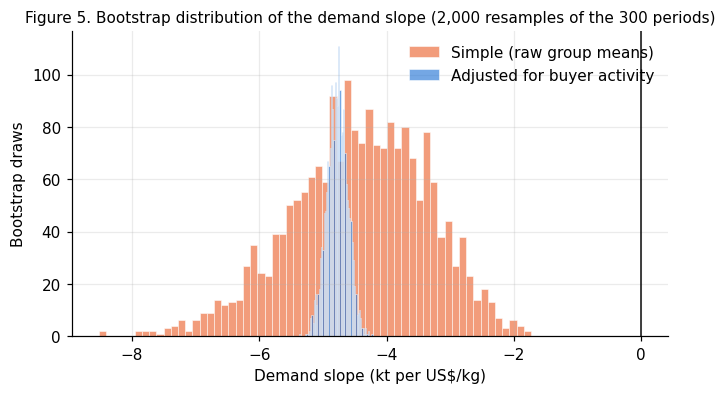

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for (k, v), colr in zip(boot.items(), [ORANGE, BLUE]):
    ax.hist(v, bins=60, color=colr, alpha=0.65, edgecolor="white", linewidth=0.5, label=k)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Demand slope (kt per US$/kg)"); ax.set_ylabel("Bootstrap draws")
ax.set_title("Figure 4. Bootstrap distribution of the demand slope (2,000 resamples of the 300 periods)", fontsize=10)
ax.legend(frameon=False); plt.show()

In [14]:
means = coff_mark.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].agg(["mean", "sem"])
print("Table 3: Mean and standard error of price (USD/kg) and quantity (kt), n = 100 per group")
print(means.round(2))

m = coff_mark.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].mean()
dP = m.loc[1.5, "price_usd_kg"] - m.loc[-1.5, "price_usd_kg"]
dQ = m.loc[1.5, "quantity_kt"] - m.loc[-1.5, "quantity_kt"]
raw_slope = dQ / dP
P_mid_raw = (m.loc[1.5, "price_usd_kg"] + m.loc[-1.5, "price_usd_kg"]) / 2
Q_mid_raw = (m.loc[1.5, "quantity_kt"] + m.loc[-1.5, "quantity_kt"]) / 2
raw_elast = raw_slope * P_mid_raw / Q_mid_raw

print(f"\nFavourable vs unfavourable: ΔP = {dP:.2f} USD/kg, ΔQ = {dQ:.2f} kt")
print(f"Demand slope: {raw_slope:.2f} kt per USD/kg; elasticity at midpoint "
      f"(P = {P_mid_raw:.2f}, Q = {Q_mid_raw:.1f}): {raw_elast:.2f}")


Table 3: Mean and standard error of price (USD/kg) and quantity (kt), n = 100 per group
                   price_usd_kg       quantity_kt      
                           mean   sem        mean   sem
growing_conditions                                     
-1.5                      11.57  0.17       91.69  1.66
 0.0                      10.20  0.17      102.04  1.76
 1.5                       8.25  0.18      106.31  1.81

Favourable vs unfavourable: ΔP = -3.32 USD/kg, ΔQ = 14.63 kt
Demand slope: -4.40 kt per USD/kg; elasticity at midpoint (P = 9.91, Q = 99.0): -0.44


In [15]:
pooled_slope, pooled_int = np.polyfit(coff_mark["price_usd_kg"], coff_mark["quantity_kt"], 1)
pooled_elast = pooled_slope * coff_mark["price_usd_kg"].mean() / coff_mark["quantity_kt"].mean()
print(f"Pooled line (all 300 points): slope {pooled_slope:.2f} kt per USD/kg, elasticity {pooled_elast:.2f}")

Pooled line (all 300 points): slope 4.49 kt per USD/kg, elasticity 0.45


In [16]:
import statsmodels.formula.api as smf

model_q = smf.ols("quantity_kt ~ C(growing_conditions) + buyer_activity", data=coff_mark).fit()
model_p = smf.ols("price_usd_kg ~ C(growing_conditions) + buyer_activity", data=coff_mark).fit()
grid = pd.DataFrame({"growing_conditions": [-1.5, 0.0, 1.5], "buyer_activity": [0, 0, 0]})
grid = grid.assign(Q_adj=model_q.predict(grid), P_adj=model_p.predict(grid))
print("Table 4: Group means at buyer_activity = 0")
print(grid.round(2))

lo, hi = grid.iloc[0], grid.iloc[2]
slope = (hi["Q_adj"] - lo["Q_adj"]) / (hi["P_adj"] - lo["P_adj"])
P_mid, Q_mid = (lo["P_adj"] + hi["P_adj"]) / 2, (lo["Q_adj"] + hi["Q_adj"]) / 2
elast = slope * P_mid / Q_mid
print(f"\nAdjusted slope: {slope:.2f} kt per USD/kg; elasticity at P = {P_mid:.2f}, Q = {Q_mid:.1f}: {elast:.2f}")

Q_line = Q_mid + slope * (grid.loc[1, "P_adj"] - P_mid)
print(f"Normal group: actual Q = {grid.loc[1, 'Q_adj']:.1f}, line predicts {Q_line:.1f}")


Table 4: Group means at buyer_activity = 0
   growing_conditions  buyer_activity   Q_adj  P_adj
0                -1.5               0   92.37  11.64
1                 0.0               0  100.01  10.00
2                 1.5               0  107.84   8.40

Adjusted slope: -4.78 kt per USD/kg; elasticity at P = 10.02, Q = 100.1: -0.48
Normal group: actual Q = 100.0, line predicts 100.2


In [17]:
def group_slope(d):
    g = d.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].mean()
    return ((g.loc[1.5, "quantity_kt"] - g.loc[-1.5, "quantity_kt"]) /
            (g.loc[1.5, "price_usd_kg"] - g.loc[-1.5, "price_usd_kg"]))

# (a) Does the slope change with buyer conditions?
print(f"Slope, low buyer activity (< 0):   {group_slope(coff_mark[coff_mark['buyer_activity'] < 0]):.2f}")
print(f"Slope, high buyer activity (>= 0): {group_slope(coff_mark[coff_mark['buyer_activity'] >= 0]):.2f}")

Slope, low buyer activity (< 0):   -4.05
Slope, high buyer activity (>= 0): -4.84


**Finding (Q3)**

**Main result**
- Good vs bad harvest: P down 3.3 USD/kg, Q up 14.6 kt.
- Slope −4.4: 1 USD/kg more means about 4.4 kt less.
- Elasticity −0.44 at P ≈ 10, Q ≈ 100. Inelastic: 1% more price means about 0.44% less bought.
- With buyer activity held at 0: slope −4.8, elasticity −0.48.
- Inelastic demand explains why bad harvests earn more.

**Why a line works**
- Only supply moves, so both group averages are on the same D curve.
- The normal group is almost exactly on the line (100.0 vs 100.2).

**Pooled line**
- +4.5, the wrong sign. It mostly traces supply (Figure 2).

**Buyer conditions**
- Controlling for them: −4.4 becomes −4.8.
- Low vs high activity: −4.1 vs −4.8.
- The conclusion doesn't change.

**Checked vs assumed**
- Checked: balance across groups, normal group on the line, stable slope.
- Assumed: weather has nothing to do with unobserved demand, and there's no storage.
- What would make us doubt it: big imbalance, normal group off the line, very different slopes.

**Uncertainty**
- Resampling (Q3.2): slope −6.7 to −2.5 with raw group means, −5.1 to −4.5 adjusted for buyer activity.
- Always negative and inelastic, but the exact size is unsure (only 3 averages).
- Only valid for prices of about 8–12 USD/kg.

## Q4: Investigate two price increases

In [18]:
# Link Q4 to the Q3 demand estimate
slope = slope_adj
P_mid = (adj.loc[-1.5, "P at B=0"] + adj.loc[1.5, "P at B=0"]) / 2
Q_mid = (adj.loc[-1.5, "Q at B=0"] + adj.loc[1.5, "Q at B=0"]) / 2
q_line = np.linspace(85, 115, 50)

In [19]:
ep = pd.read_csv("data/coffee_episodes.csv")
ep = ep.assign(revenue_musd=ep["price_usd_kg"] * ep["quantity_kt"])

cols = ["price_usd_kg", "quantity_kt", "revenue_musd", "growing_conditions", "buyer_activity"]
ep_means = ep.groupby(["episode", "phase"])[cols].mean()
print("Table 5: Episode averages (n = 10 per cell)")
print(ep_means.round(2))

changes = (ep_means.xs("During", level="phase") - ep_means.xs("Before", level="phase"))
changes = changes.assign(revenue_pct=100 * changes["revenue_musd"]
                         / ep_means.xs("Before", level="phase")["revenue_musd"])
print("\nTable 6: Change, During minus Before")
print(changes.round(2))

Table 7: Episode averages (n = 10 per cell)
                price_usd_kg  quantity_kt  revenue_musd  growing_conditions  \
episode phase                                                                 
A       Before          9.98       100.00        997.94                 0.0   
        During         11.55        91.71       1059.24                -1.5   
B       Before         10.04       100.13       1004.87                 0.0   
        During         11.64       116.39       1354.23                 0.0   

                buyer_activity  
episode phase                   
A       Before             0.0  
        During             0.0  
B       Before             0.0  
        During             1.6  

Table 8: Change, During minus Before
         price_usd_kg  quantity_kt  revenue_musd  growing_conditions  \
episode                                                                
A                1.57        -8.29         61.29                -1.5   
B                1.60        

In [20]:
dP_A = changes.loc["A", "price_usd_kg"]
dQ_A = changes.loc["A", "quantity_kt"]
print(f"Episode A: price +{dP_A:.2f} USD/kg; actual ΔQ = {dQ_A:.2f} kt; "
      f"demand slope predicts ΔQ = {slope * dP_A:.2f} kt")

Episode A: price +1.57 USD/kg; actual ΔQ = -8.29 kt; demand slope predicts ΔQ = -7.50 kt


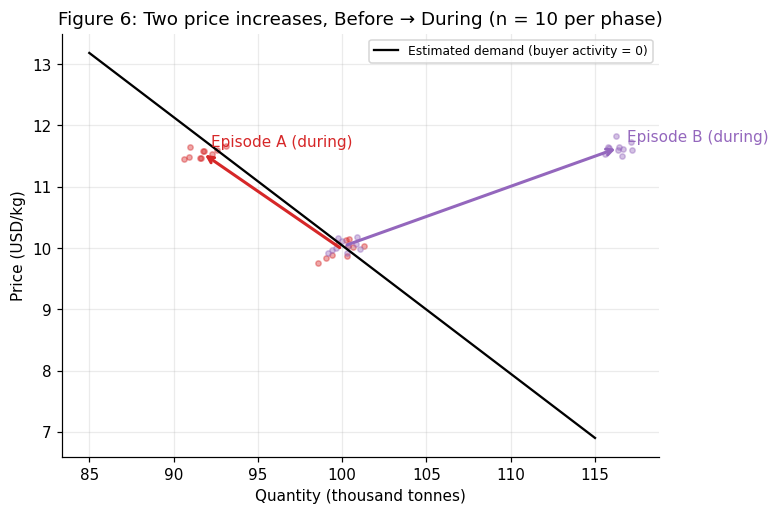

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, color in [("A", "tab:red"), ("B", "tab:purple")]:
    before = ep_means.loc[(name, "Before")]
    during = ep_means.loc[(name, "During")]
    pts = ep[ep["episode"] == name]
    ax.scatter(pts["quantity_kt"], pts["price_usd_kg"], s=12, alpha=0.4, color=color)
    ax.annotate("", xy=(during["quantity_kt"], during["price_usd_kg"]),
                xytext=(before["quantity_kt"], before["price_usd_kg"]),
                arrowprops=dict(arrowstyle="->", color=color, lw=2))
    ax.text(during["quantity_kt"] + 0.5, during["price_usd_kg"] + 0.1, f"Episode {name} (during)", color=color)
ax.plot(q_line, P_mid + (q_line - Q_mid) / slope, "k-", label="Estimated demand (buyer activity = 0)")
ax.set_xlabel("Quantity (thousand tonnes)")
ax.set_ylabel("Price (USD/kg)")
ax.set_title("Figure 5. Two price increases, Before → During (n = 10 per phase)")
ax.legend(fontsize=8)
plt.show()


**Finding (Q4)**
- Both episodes: price goes up about 1.6 USD/kg.
- **A:** weather goes bad (0 → −1.5), buyers unchanged.
  - Supply shifts left, so the market moves along demand.
  - Q down 8.3 kt. Our slope predicted about −7.5, close.
  - Revenue +61 million USD (+6%), but less coffee sold.
- **B:** weather normal, buyer activity up (0 → 1.6).
  - Demand shifts right, so the market moves along supply.
  - Q up 16.3 kt. Revenue +349 million USD (+35%).
  - Our elasticity doesn't apply here, because it's not a move along demand.
- **Lesson:** same price rise, very different result for sellers. The cause matters.
- **We can't say:**
  - Profits went up: no cost data.
  - Every farmer gained: no farm-level data, and in A some farmers lost their crop.
  - Society is better off: in A, buyers pay more for less coffee and less is traded. To be sure we'd need buyer surplus and costs.
- Only 10 periods per phase, but the differences are big.

---
## Q5: Predict a new market outcome

### Q5.1 New scenario

`coffee_forecast_scenarios.csv` describes a **short selling window after harvest**:
- The coffee is already harvested and committed to sale. There is **no storage, no imports, no alternative outlet**, so all of it is sold whatever the price.
- Supply is **perfectly inelastic** at the available volume $\bar Q$. Price no longer changes how much is offered. It only decides **who buys** the fixed amount.
- The demand curve from Q3 remains valid.

Equilibrium is where the demand curve meets the vertical supply line:

$$D(P^*) = a + b\,P^* = \bar Q \quad\Longrightarrow\quad P^* = \frac{a - \bar Q}{-b}, \qquad \text{Revenue} = P^* \times \bar Q .$$


### Q5.2 The demand curve at reference conditions

We need the **level** of demand (intercept $a$) as well as the slope $b$. We take both from the Q3 logic: 
1) predict price from the weather and buyer activity
2) regress quantity on that weather-driven price and buyer activity. 

Step (2) uses only the price variation caused by the weather, so its price coefficient equals the Q3 adjusted slope. Setting B = 0 gives the reference demand curve.

In [22]:
def fit_demand(d):
    G, B = d["growing_conditions"], d["buyer_activity"]
    cP = ols(d["price_usd_kg"], G, B)
    P_weather = cP[0] + cP[1] * G + cP[2] * B        # price explained by weather (and B)
    a, b, c = ols(d["quantity_kt"], P_weather, B)     # Q = a + b*P + c*B
    return a, b, c

a_D, b_D, c_D = fit_demand(coff_mark)
print(f"Demand: Q = {a_D:.1f} {b_D:+.2f}·P {c_D:+.1f}·buyer_activity")
print(f"At reference (B = 0): Q = {a_D:.1f} {b_D:+.2f}·P   (slope = Q3 adjusted slope {slope_adj:.2f})")

scen = pd.read_csv("data/coffee_forecast_scenarios.csv")
scen

Demand: Q = 147.9 -4.78·P +14.9·buyer_activity
At reference (B = 0): Q = 147.9 -4.78·P   (slope = Q3 adjusted slope -4.78)


,scenario,release_kt,buyer_activity,explanation
0,Normal release,100,0,Normal reference volume committed to sale
1,Smaller release,92,0,"Eight percent less than normal, all committed ..."


### Q5.3 Predictions: price and revenue in each scenario

In [23]:
def p_star(Qbar, a=a_D, b=b_D): return (a - Qbar) / (-b)

pred = scen[["scenario", "release_kt"]].copy()
pred["pred_price_usd_kg"] = p_star(pred["release_kt"])
pred["pred_revenue_musd"] = pred["pred_price_usd_kg"] * pred["release_kt"]

# What the pooled Q1 line would predict (treating it as if it were demand)
b_pool, a_pool = np.polyfit(coff_mark["price_usd_kg"], coff_mark["quantity_kt"], 1)
pred["pooled_line_price"] = (pred["release_kt"] - a_pool) / b_pool
pred["pooled_line_revenue"] = pred["pooled_line_price"] * pred["release_kt"]
pred.round(2)

/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_15025/1336184275.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  pred["pred_price_usd_kg"] = p_star(pred["release_kt"])
/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel

,scenario,release_kt,pred_price_usd_kg,pred_revenue_musd,pooled_line_price,pooled_line_revenue
0,Normal release,100,10.03,1002.82,10.00,1000.39
1,Smaller release,92,11.70,1076.64,8.22,756.39


In [24]:
n, s = pred.set_index("scenario").loc["Normal release"], pred.set_index("scenario").loc["Smaller release"]
pct = lambda new, old: 100 * (new / old - 1)
print(f"Quantity: {pct(s.release_kt, n.release_kt):+.1f}%")
print(f"Price:    {pct(s.pred_price_usd_kg, n.pred_price_usd_kg):+.1f}%")
print(f"Revenue:  {pct(s.pred_revenue_musd, n.pred_revenue_musd):+.1f}%")

# The disequilibrium story: harvest falls but price initially stays at the normal level
P_old = n.pred_price_usd_kg
desired = a_D + b_D * P_old
print(f"\nAt the old price {P_old:.2f}: buyers want {desired:.1f} kt but only {s.release_kt:.0f} kt is available "
      f"→ excess demand of {desired - s.release_kt:.1f} kt")
print(f"Price rise needed to choke off that excess demand: {(desired - s.release_kt) / -b_D:.2f} US$/kg")

Quantity: -8.0%
Price:    +16.7%
Revenue:  +7.4%

At the old price 10.03: buyers want 100.0 kt but only 92 kt is available → excess demand of 8.0 kt
Price rise needed to choke off that excess demand: 1.67 US$/kg


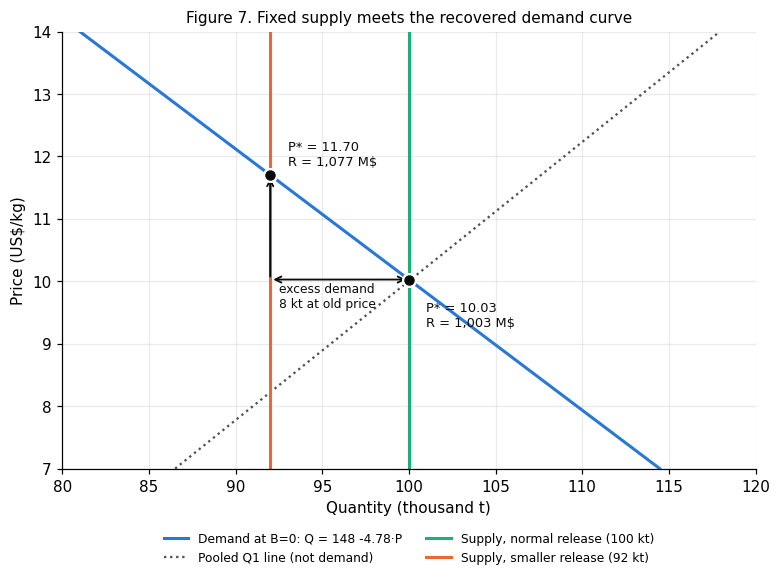

In [25]:
fig, ax = plt.subplots(figsize=(7.2, 5.4))
pg = np.linspace(7, 14, 50)
ax.plot(a_D + b_D * pg, pg, color=BLUE, lw=2, label=f"Demand at B=0: Q = {a_D:.0f} {b_D:.2f}·P")
ax.plot(a_pool + b_pool * pg, pg, color=MUTED, lw=1.5, ls=":", label="Pooled Q1 line (not demand)")
for Qbar, colr, lab in [(100, AQUA, "Supply, normal release (100 kt)"), (92, ORANGE, "Supply, smaller release (92 kt)")]:
    ax.axvline(Qbar, color=colr, lw=2, label=lab)
    P = p_star(Qbar)
    ax.scatter([Qbar], [P], s=70, color=INK, zorder=5, edgecolor="white", linewidth=1.5)
    dy = 0.15 if Qbar == 92 else -0.75
    ax.text(Qbar + 1, P + dy, f"P* = {P:.2f}\nR = {P*Qbar:,.0f} M$", fontsize=8.5, color=INK)
# excess demand at the old price
ax.annotate("", xy=(desired, P_old), xytext=(92, P_old),
            arrowprops=dict(arrowstyle="<->", color=INK, lw=1.2))
ax.text(92.5, P_old - 0.45, f"excess demand\n{desired - 92:.0f} kt at old price", fontsize=8, color=INK)
ax.annotate("", xy=(92, p_star(92)), xytext=(92, P_old), arrowprops=dict(arrowstyle="->", color=INK, lw=1.2))
ax.set_xlim(80, 120); ax.set_ylim(7, 14)
ax.set_xlabel("Quantity (thousand t)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 6. Fixed supply meets the recovered demand curve", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout(); plt.show()

- With 100 kt the price settles at about the reference level (≈ US\$10/kg, revenue ≈ US\$1.0 bn).
- With 8% less coffee the price must rise until buyers *want* only 92 kt. Because demand is inelastic (|ε| ≈ 0.5), this takes a price rise of about 17% (8% ÷ 0.48). Revenue therefore **rises** by about 7%: sellers earn more by selling less.
- **Disequilibrium:** if the price stayed at the old level, buyers would want about 100 kt but only 92 kt exist. Buyers who miss out offer more, the price is bid up, and some buyers drop out along the demand curve until the remaining desired purchases equal 92 kt.
- **The pooled line predicts the opposite:** a *lower* price (≈ US\$8.2) and revenue falling by about a quarter, because it treats a supply curve as if it were demand.


### Q5.4 How uncertain is the prediction?

There are two different questions here:
1. **The average price** across many such selling windows. Its uncertainty comes from estimating $a$ and $b$ from 300 periods.
2. **The price in one single window.** That period's own demand disturbance moves the demand curve left or right. With vertical supply, a demand shock of $u$ kt moves the price by $u/|b|$.

In [26]:
rng = np.random.default_rng(2026)
boot_P = []
for _ in range(2000):
    d = coff_mark.iloc[rng.integers(0, len(coff_mark), len(coff_mark))]
    a_, b_, _ = fit_demand(d)
    boot_P.append([p_star(100, a_, b_), p_star(92, a_, b_)])
boot_P = np.array(boot_P)

u = coff_mark["quantity_kt"] - (a_D + b_D * coff_mark["price_usd_kg"] + c_D * coff_mark["buyer_activity"])   # demand disturbances
sd_P_single = u.std() / -b_D

pred["avg_price_low"]  = np.percentile(boot_P, 2.5, axis=0)
pred["avg_price_high"] = np.percentile(boot_P, 97.5, axis=0)
pred["single_window_low"]  = pred["pred_price_usd_kg"] - 1.96 * sd_P_single
pred["single_window_high"] = pred["pred_price_usd_kg"] + 1.96 * sd_P_single
print(f"sd of demand disturbances ≈ {u.std():.2f} kt → sd of a single window's price ≈ {sd_P_single:.2f} US$/kg")
pred[["scenario", "pred_price_usd_kg", "avg_price_low", "avg_price_high",
      "single_window_low", "single_window_high", "pred_revenue_musd"]].round(2)

sd of demand disturbances ≈ 3.84 kt → sd of a single window's price ≈ 0.80 US$/kg


/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_15025/3289652366.py:14: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  pred["single_window_low"]  = pred["pred_price_usd_kg"] - 1.96 * sd_P_single
/var/folders/t9/0f6k77l54153159xk5l1

,scenario,pred_price_usd_kg,avg_price_low,avg_price_high,single_window_low,single_window_high,pred_revenue_musd
0,Normal release,10.03,9.93,10.12,8.45,11.60,1002.82
1,Smaller release,11.70,11.56,11.85,10.13,13.28,1076.64


### Q5.5 Record the predictions

The next cell saves the predictions with a time stamp, so it is documented that they were made before seeing `coffee_forecast_reveal.csv`.

In [27]:
from datetime import datetime
pred["recorded_at"] = datetime.now().isoformat(timespec="seconds")
pred.to_csv("q5_predictions_recorded.csv", index=False)
pred[["scenario", "release_kt", "pred_price_usd_kg", "pred_revenue_musd", "recorded_at"]].round(2)

/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_15025/2158248082.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  pred["recorded_at"] = datetime.now().isoformat(timespec="seconds")


,scenario,release_kt,pred_price_usd_kg,pred_revenue_musd,recorded_at
0,Normal release,100,10.03,1002.82,2026-10-31T10:17:19
1,Smaller release,92,11.70,1076.64,2026-10-31T10:17:19


### Q5.6 Compare with the new evidence (no refitting)

`coffee_forecast_reveal.csv`: 40 independent realisations of each scenario. We only compare.

In [28]:
assert Path("q5_predictions_recorded.csv").exists(), "Record the predictions first (5.5)"
rev = pd.read_csv("data/coffee_forecast_reveal.csv")
rev["revenue_musd"] = rev["price_usd_kg"] * rev["quantity_kt"]
obs = (rev.groupby("scenario")
          .agg(n=("price_usd_kg", "size"), mean_price=("price_usd_kg", "mean"),
               sd_price=("price_usd_kg", "std"), min_price=("price_usd_kg", "min"),
               max_price=("price_usd_kg", "max"), mean_revenue=("revenue_musd", "mean")))
obs["se_mean_price"] = obs["sd_price"] / np.sqrt(obs["n"])
cmp_ = obs.join(pred.set_index("scenario")[["pred_price_usd_kg", "avg_price_low", "avg_price_high",
                                             "single_window_low", "single_window_high", "pred_revenue_musd"]])
cmp_["error_mean_price"] = cmp_["mean_price"] - cmp_["pred_price_usd_kg"]
cmp_["share_in_single_band"] = [rev.loc[rev.scenario == s, "price_usd_kg"].between(r.single_window_low, r.single_window_high).mean()
                                for s, r in cmp_.iterrows()]
cmp_.T.round(2)

/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_15025/398125074.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  rev["revenue_musd"] = rev["price_usd_kg"] * rev["quantity_kt"]
/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ip

scenario,Normal release,Smaller release
n,40.00,40.00
mean_price,10.09,11.69
sd_price,0.77,0.73
min_price,8.59,10.23
max_price,11.56,13.42
mean_revenue,1009.13,1075.42
se_mean_price,0.12,0.12
pred_price_usd_kg,10.03,11.70
avg_price_low,9.93,11.56
avg_price_high,10.12,11.85


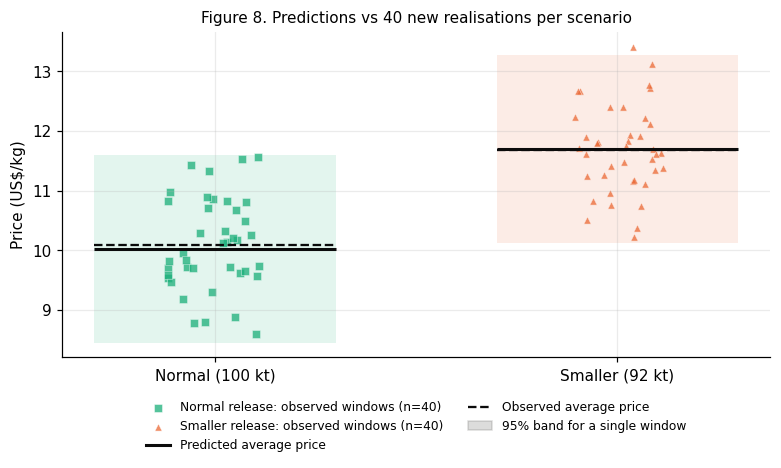

In [29]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for i, (sc, colr, mk) in enumerate([("Normal release", AQUA, "s"), ("Smaller release", ORANGE, "^")]):
    y = rev.loc[rev.scenario == sc, "price_usd_kg"]
    x = i + rng.uniform(-0.12, 0.12, len(y))
    ax.scatter(x, y, s=22, color=colr, marker=mk, alpha=0.75, edgecolor="white", linewidth=0.4,
               label=f"{sc}: observed windows (n={len(y)})")
    r = cmp_.loc[sc]
    ax.fill_between([i - 0.3, i + 0.3], r.single_window_low, r.single_window_high, color=colr, alpha=0.12, lw=0)
    ax.hlines(r.pred_price_usd_kg, i - 0.3, i + 0.3, color=INK, lw=2)
    ax.hlines(r.mean_price, i - 0.3, i + 0.3, color=INK, lw=1.5, ls="--")
ax.plot([], [], color=INK, lw=2, label="Predicted average price")
ax.plot([], [], color=INK, lw=1.5, ls="--", label="Observed average price")
ax.fill_between([], [], [], color=MUTED, alpha=0.2, label="95% band for a single window")
ax.set_xticks([0, 1], ["Normal (100 kt)", "Smaller (92 kt)"]); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 7. Predictions vs 40 new realisations per scenario", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout(); plt.show()

---
## Q6: Consider a tax on sales

### Q6.1 The setting: supply is fixed

We return to the normal-volume scenario from Q5: 100 kt of coffee is already harvested and must all be sold. There is no storage, no imports and no other outlet. The government adds a tax of **$1 per kg**, paid by sellers on every kg sold.

What does this mean for supply?
- Sellers cannot sell less: the coffee is already harvested and must be sold, whatever the price.
- So supply is **vertical** (perfectly inelastic) at 100 kt.
- The tax therefore cannot change the quantity traded.

Demand does not shift either. The tax does not change what buyers want, so we keep the demand curve from Q3/Q5 (Q = 147.9 − 4.78·P at buyer activity = 0). A change in price only moves buyers *along* this curve.

This is also why we do not need to estimate supply: with a vertical supply line, only the demand curve decides the price.

### Q6.2 Prices, quantity and revenues

In [30]:
t = 1.0                                  # tax in USD per kg, paid by sellers
Q_fixed = 100                            # kt, normal release (fixed supply)

P_buy = p_star(Q_fixed)                  # buyers' price: where demand equals 100 kt (as in Q5)
P_sell = P_buy - t                       # sellers keep the buyers' price minus the tax

gov_revenue = t * Q_fixed                # USD/kg x kt = million USD
receipts_before = P_buy * Q_fixed        # seller receipts without the tax
receipts_after = P_sell * Q_fixed        # seller receipts after paying the tax

table9 = pd.DataFrame({
    "no tax": [Q_fixed, P_buy, P_buy, 0, receipts_before],
    "with $1 tax": [Q_fixed, P_buy, P_sell, gov_revenue, receipts_after],
}, index=["Quantity (kt)", "Price buyers pay (USD/kg)", "Price sellers keep (USD/kg)",
          "Government revenue (million USD)", "Seller receipts after tax (million USD)"])
table9["change"] = table9["with $1 tax"] - table9["no tax"]

print("Table 7: Effect of a $1/kg tax on sellers, normal release (100 kt)")
table9.round(2)

Table 9: Effect of a $1/kg tax on sellers, normal release (100 kt)


/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_15025/3287694314.py:16: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  table9["change"] = table9["with $1 tax"] - table9["no tax"]


,no tax,with $1 tax,change
Quantity (kt),100.00,100.00,0.0
Price buyers pay (USD/kg),10.03,10.03,0.0
Price sellers keep (USD/kg),10.03,9.03,-1.0
Government revenue (million USD),0.00,100.00,100.0
Seller receipts after tax (million USD),1002.82,902.82,-100.0


**Reading Table 7**
- The quantity stays at 100 kt, because supply is fixed.
- Buyers still pay 10.03 USD/kg: at that price they want exactly the 100 kt that is available.
- Sellers keep 10.03 − 1 = 9.03 USD/kg.
- Government revenue: 1 USD/kg × 100 kt = 100 million kg × 1 USD = **100 million USD**.
- Seller receipts after tax fall by 100 million USD (about −10%), exactly the amount the government collects.

### Q6.3 Who bears the tax?

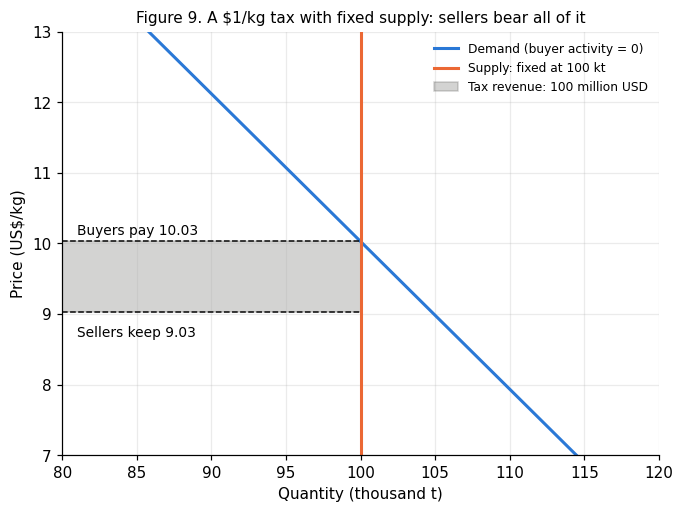

In [31]:
pg = np.linspace(7, 13, 50)              # price range for drawing the demand line

fig, ax = plt.subplots(figsize=(7, 5))

# Demand from Q3/Q5 and the vertical supply line at 100 kt
ax.plot(a_D + b_D * pg, pg, color=BLUE, lw=2, label="Demand (buyer activity = 0)")
ax.axvline(Q_fixed, color=ORANGE, lw=2, label="Supply: fixed at 100 kt")

# The two prices: what buyers pay and what sellers keep
ax.hlines(P_buy, 80, Q_fixed, color=INK, ls="--", lw=1)
ax.hlines(P_sell, 80, Q_fixed, color=INK, ls="--", lw=1)
ax.text(81, P_buy + 0.1, f"Buyers pay {P_buy:.2f}", fontsize=9)
ax.text(81, P_sell - 0.35, f"Sellers keep {P_sell:.2f}", fontsize=9)

# Shaded rectangle between the two prices = government revenue
ax.fill_between([80, Q_fixed], P_sell, P_buy, color=MUTED, alpha=0.25,
                label=f"Tax revenue: {gov_revenue:.0f} million USD")

ax.set_xlim(80, 120); ax.set_ylim(7, 13)
ax.set_xlabel("Quantity (thousand t)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 8. A $1/kg tax with fixed supply: sellers bear all of it", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.show()

**Who bears the tax? (Figure 8)**
- The tax creates a gap of 1 USD/kg between what buyers pay and what sellers keep.
- Buyers pay the same price as before (10.03), because the quantity they get has not changed.
- So the whole gap falls on sellers: they keep 9.03 instead of 10.03.
- **Sellers bear 100% of the tax, buyers 0%.**
- Reason: sellers cannot respond by selling less. The side that cannot get out of the way pays the tax.

### Q6.4 Surplus and deadweight loss

In [32]:
# Change in surplus caused by the tax (million USD per selling period)
# - Consumer surplus: buyers pay the same price for the same quantity -> no change
# - Producer surplus: sellers lose exactly the tax they pay (harvest costs are already sunk)
# - Government: collects the tax
cs_change = 0
ps_change = receipts_after - receipts_before     # = -100
gov_change = gov_revenue                        # = +100
total_change = cs_change + ps_change + gov_change

table10 = pd.DataFrame({
    "change (million USD)": [cs_change, ps_change, gov_change, total_change]
}, index=["Consumer surplus", "Producer surplus", "Government revenue",
          "Total surplus (− = deadweight loss)"])

print("Table 8: Change in surplus caused by the $1/kg tax (normal release, 100 kt)")
table10.round(1)

Table 10: Change in surplus caused by the $1/kg tax (normal release, 100 kt)


,change (million USD)
Consumer surplus,0.0
Producer surplus,-100.0
Government revenue,100.0
Total surplus (− = deadweight loss),0.0


**Is there a deadweight loss? (Table 8)**
- A deadweight loss happens when a tax stops trades that would have been worth making.
- Here the quantity stays at 100 kt, so every trade still happens.
- Buyers lose nothing (same price, same quantity). Sellers lose 100 million USD, and the government gains exactly that 100 million USD.
- Total surplus does not change: **no deadweight loss**. The tax is a pure transfer from sellers to the government.
- In Figure 8 this shows up as a rectangle (tax revenue) and no triangle: a deadweight-loss triangle only appears when the quantity falls.

### Q6.5 Does the legal payer matter?

In [33]:
# Case 1: sellers pay the tax (as in 6.2)
seller_case = {"Buyers pay in total (USD/kg)": P_buy,
               "Sellers keep (USD/kg)": P_buy - t,
               "Quantity (kt)": Q_fixed}

# Case 2: buyers pay the tax on top of the price they give sellers.
# Buyers care about their total cost: P_seller + t.
# They still want exactly 100 kt only at a total cost of p_star(100) = 10.03,
# so the price that goes to sellers must be 10.03 - 1.
P_seller_buyerpays = p_star(Q_fixed) - t
buyer_case = {"Buyers pay in total (USD/kg)": P_seller_buyerpays + t,
              "Sellers keep (USD/kg)": P_seller_buyerpays,
              "Quantity (kt)": Q_fixed}

table11 = pd.DataFrame({"Sellers pay the tax": seller_case,
                        "Buyers pay the tax": buyer_case})
print("Table 9: Same $1 tax, different legal payer")
table11.round(2)

Table 11: Same $1 tax, different legal payer


,Sellers pay the tax,Buyers pay the tax
Buyers pay in total (USD/kg),10.03,10.03
Sellers keep (USD/kg),9.03,9.03
Quantity (kt),100.00,100.00


**Does it matter who legally pays? (Table 9)**
- If buyers paid the tax, they would look at their total cost per kg: the price to the seller plus the 1 USD tax.
- Seen from the sellers' side, demand shifts down by 1 USD: buyers are only willing to pay sellers 1 USD less for the same 100 kt.
- Buyers still pay 10.03 in total, sellers still keep 9.03, and 100 kt is still traded.
- **The result is exactly the same.** Who legally pays does not matter; only the 1 USD gap between the buyers' price and the sellers' price does.

### Q6.6 Which assumption drives the result?

**Key assumption: supply is fixed.** In this short selling window the coffee is already harvested and must all be sold. Sellers cannot react to a lower net price by selling less, so they carry the whole tax and the quantity does not change.

**Over a longer horizon this changes.** The brief says that over normal selling periods sellers *can* adjust harvesting, processing and sales effort. Then:
- A lower net price makes sellers supply less, so supply slopes **up** instead of being vertical.
- The quantity traded **falls**.
- The tax is **shared**: buyers pay more and sellers keep less. Because demand is inelastic (|ε| ≈ 0.48), buyers can carry a large part of it.
- Some trades that were worth making no longer happen, so a **deadweight loss** appears.

Figure 9 illustrates this with a made-up supply slope. It is not an estimate (the brief does not require us to estimate supply).

Illustrative longer horizon (supply slope 0.15):
  Quantity: -2.8 kt | Buyers pay +0.58 | Sellers keep -0.42 USD/kg
  Buyers' share of the tax: 58% | Deadweight loss: 1.4 million USD


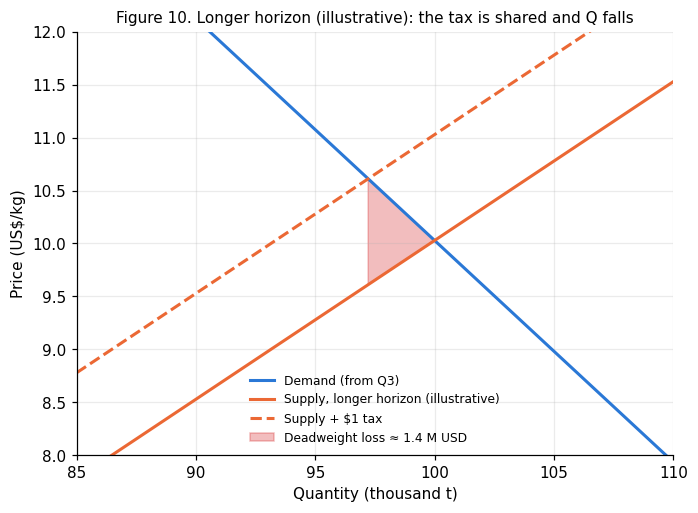

In [34]:
# ILLUSTRATIVE ONLY: an upward-sloping supply curve for a longer horizon.
s = 0.15                     # made-up supply slope: USD/kg per extra kt
m = 1 / -b_D                 # demand slope in USD/kg per kt, from Q3 (about 0.21)

# Solve the new equilibrium with the tax (changes relative to the no-tax point: 100 kt, P_buy)
dQ = -t / (m + s)                    # change in quantity
dP_buyers = t * m / (m + s)          # buyers' price goes up by this
dP_sellers = -t * s / (m + s)        # sellers' net price goes down by this
dwl = 0.5 * t * (-dQ)                # deadweight-loss triangle, million USD

print(f"Illustrative longer horizon (supply slope {s}):")
print(f"  Quantity: {dQ:+.1f} kt | Buyers pay {dP_buyers:+.2f} | Sellers keep {dP_sellers:+.2f} USD/kg")
print(f"  Buyers' share of the tax: {dP_buyers / t:.0%} | Deadweight loss: {dwl:.1f} million USD")

qg = np.linspace(85, 110, 50)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(qg, P_buy - m * (qg - 100), color=BLUE, lw=2, label="Demand (from Q3)")
ax.plot(qg, P_buy + s * (qg - 100), color=ORANGE, lw=2, label="Supply, longer horizon (illustrative)")
ax.plot(qg, P_buy + t + s * (qg - 100), color=ORANGE, lw=2, ls="--", label="Supply + $1 tax")

# Shade the deadweight-loss triangle between the old and new quantity
Q_new = 100 + dQ
ax.fill([Q_new, 100, Q_new], [P_buy + dP_buyers, P_buy, P_buy + dP_sellers],
        color="tab:red", alpha=0.3, label=f"Deadweight loss ≈ {dwl:.1f} M USD")

ax.set_xlim(85, 110); ax.set_ylim(8, 12)
ax.set_xlabel("Quantity (thousand t)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 9. Longer horizon (illustrative): the tax is shared and Q falls", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.show()

**Finding (Q6)**

**Main result** (Table 7, Figure 8)
- Supply is fixed at 100 kt, so the quantity does not change.
- Buyers still pay 10.03 USD/kg; sellers keep 9.03 USD/kg after the tax.
- Government revenue: 100 million USD per selling period.
- Seller receipts after tax: 1,003 → 903 million USD (−100 M, about −10%).

**Who bears the tax**
- Sellers bear 100%, buyers 0%.
- Sellers cannot sell less, so they cannot pass the tax on.

**Deadweight loss** (Table 8)
- None: the same 100 kt is still traded.
- Consumer surplus 0, producer surplus −100, government +100, total 0. The tax is a pure transfer.

**Legal payer** (Table 9)
- If buyers paid the tax, buyers would still pay 10.03 in total and sellers would still keep 9.03.
- Who legally pays does not matter; only the 1 USD gap between the two prices does.

**Key assumption**
- Fixed supply in a short selling window drives the whole result.
- Over a longer horizon sellers can cut harvesting and sales effort. Supply then slopes up, Q falls, buyers pay part of the tax (a large part, as demand is inelastic) and a deadweight loss appears (Figure 9, illustrative).

## Q7: Briefing for the producers' organisation

Coffee prices move for two reasons. Bad growing conditions mean less coffee is harvested, so the price rises. Stronger buyer activity abroad means buyers want more coffee, so the price also rises. A higher price on its own therefore does not tell you which of the two happened. The quantity sold does: with stronger demand more coffee is sold, after a bad harvest less.

When demand rises, seller revenue clearly goes up, because both price and quantity increase (in one period of stronger demand we observed, revenue rose by about 35%). After a bad harvest revenue also rises, but for a different reason. Buyers react only weakly to price: a 1% higher price reduces purchases by only about 0.48%. So the price rise outweighs the lost volume. In our data, periods with unfavourable conditions earned about 1,089 million USD against 909 million USD with favourable conditions.

Our scenarios follow the same logic. If 8% less coffee is available, we predict a price about 17% higher and revenue about 7% higher, and the new data in Q5 matched our average prediction closely. A tax of 1 USD per kg in a short selling window falls fully on sellers, because the harvested coffee must be sold anyway: they lose about 100 million USD per period. Over a longer period, when farmers can cut back production, buyers would pay part of the tax.

These results rest on data we tested, but also on assumptions: weather is unrelated to what buyers want, quality stays the same and supply is fixed in the short window. Revenue is not profit. Before giving broader advice, we would need production costs, how revenue is shared between farmers, and data over a longer horizon. 